# Rolling-mean exit rule — when to cut a funding-carry position

Idea: the noisy funding point is unpredictable, but its **rolling mean** (EWMA) is a reliable,
smooth state. Use it as an **exit signal** — hold while the mean is healthily positive, and
**close preemptively as the mean reverts toward 0**, getting out *before* realized funding flips
negative (where we'd start paying). This is the keep/exit side of Layer D (hysteresis).

We test, per asset, whether a mean-based exit **avoids enough negative funding to beat the carry
it forgoes + the churn cost** of exiting/re-entering. Single-name timing in isolation.

In [1]:
%matplotlib inline
import sys; from pathlib import Path
_p = Path.cwd().resolve()
ROOT = next((q for q in [_p, *_p.parents] if (q/'pyproject.toml').exists()), _p)
sys.path[:0] = [str(ROOT), str(ROOT/'research'/'funding_pred')]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import study as S
plt.rcParams.update({'figure.figsize':(14,3.6),'axes.grid':True,'grid.alpha':0.25,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
NAVY,TEAL,AMBER,RED,GREEN='#1f3a5f','#2a9d8f','#e0a32e','#c1121f','#2d6a4f'
inc, _ = S.daily_panels()                 # daily funding income (=APR/365) per asset
SYMS = list(inc.columns)
HL = 7                                     # EWMA mean halflife (days)
C_RT = 0.0038                              # round-trip cost (enter+exit), 38 bps
mean = inc.ewm(halflife=HL).mean()         # the smooth state
print('assets:', SYMS, '| days:', len(inc))

assets: ['btcusdt', 'ethusdt', 'bnbusdt', 'xrpusdt', 'solusdt'] | days: 1977


## The exit rules

All decisions use the mean **as known yesterday** (`mean.shift(1)`) — strictly causal. Thresholds
are in **annualized APR** (converted to daily income = APR/365). Hysteresis = enter on a high mean,
keep down to a lower one (stops whipsaw near the threshold).

In [2]:
def simulate(d, m, theta_in_apr, theta_keep_apr):
    """Hold/exit a single name. Returns held series + stats. m = causal EWMA mean."""
    ti, tk = theta_in_apr/365, theta_keep_apr/365
    mv = m.shift(1).to_numpy(); dv = d.to_numpy()
    held = np.zeros(len(dv)); st = 0
    for t in range(len(dv)):
        if np.isnan(mv[t]): held[t] = 0; continue
        if st == 0 and mv[t] > ti: st = 1
        elif st == 1 and mv[t] < tk: st = 0
        held[t] = st
    held = pd.Series(held, index=d.index)
    entries = int(((held.diff() == 1)).sum())
    carry = float((held*d).sum())
    neg_paid = float((held*d)[(held==1)&(d<0)].sum())     # funding paid while held (the tail)
    forgone = float(((1-held)*d)[(held==0)&(d>0)].sum())  # positive carry missed while flat
    cost = entries * C_RT
    yrs = len(d)/365
    return dict(held=held, entries=entries, carry=carry, neg_paid=neg_paid, forgone=forgone,
                cost=cost, net=carry-cost, net_apr=(carry-cost)/yrs, pct_days_held=float(held.mean()))

RULES = {
    'always_hold':  dict(theta_in_apr=-1e9, theta_keep_apr=-1e9),   # never exit
    'exit_at_0':    dict(theta_in_apr=0.0,  theta_keep_apr=0.0),     # hold while mean>0
    'preemptive':   dict(theta_in_apr=0.08, theta_keep_apr=0.02),   # enter>8% APR, exit<2% (before 0)
}

## See it on the series

ETH: funding APR (grey), the EWMA **mean** (navy), **held** periods shaded green (preemptive rule),
and **negative-funding** days shaded red. Does the rule go flat *before* the red stretches?

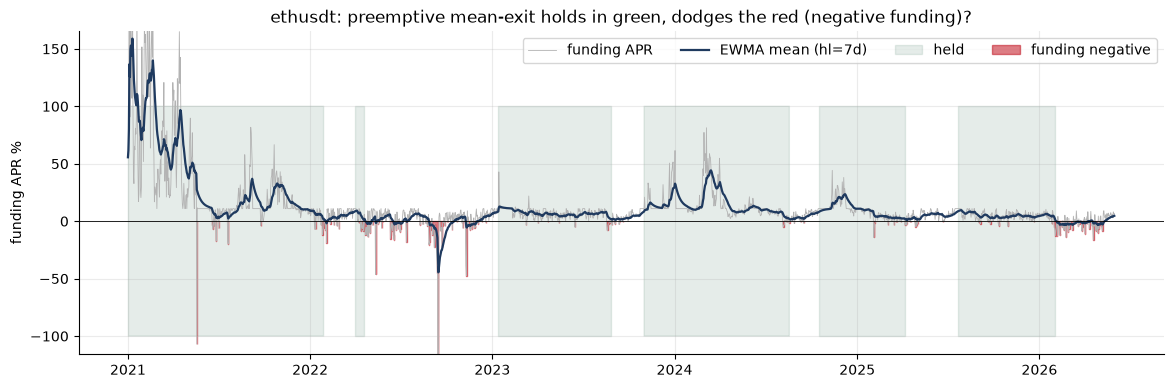

entries (round trips): 6 | days held: 66%


In [3]:
sym='ethusdt'; d=inc[sym].dropna(); m=mean[sym].reindex(d.index)
res = simulate(d, m, **RULES['preemptive']); held=res['held']
fig, ax = plt.subplots(figsize=(14,4.2))
ax.plot(d.index, d*365*100, color='0.7', lw=0.6, label='funding APR')
ax.plot(m.index, m*365*100, color=NAVY, lw=1.6, label=f'EWMA mean (hl={HL}d)')
ax.fill_between(d.index, -100, 100, where=(held==1), color=GREEN, alpha=0.12, label='held', step='mid')
ax.fill_between(d.index, d*365*100, 0, where=(d<0), color=RED, alpha=0.55, step='mid', label='funding negative')
ax.axhline(0,color='k',lw=0.6); ax.set_ylim(d.min()*365*100*0.6, d.max()*365*100*0.6)
ax.set_ylabel('funding APR %'); ax.legend(ncol=4, loc='upper right')
ax.set_title(f'{sym}: preemptive mean-exit holds in green, dodges the red (negative funding)?')
plt.show()
print(f"entries (round trips): {res['entries']} | days held: {res['pct_days_held']:.0%}")

## Does it pay? — per-asset comparison

For each rule: net carry (annualized, after round-trip costs), the **negative funding paid while
held** (lower magnitude = more flips dodged), carry **forgone** while flat, and # round trips.

In [4]:
rows=[]
for s in SYMS:
    d=inc[s].dropna(); m=mean[s].reindex(d.index)
    for name,p in RULES.items():
        r=simulate(d,m,**p)
        rows.append({'asset':s.replace('usdt','').upper(),'rule':name,
                     'net_apr_%':r['net_apr']*100,'carry_%':r['carry']*100,
                     'neg_paid_%':r['neg_paid']*100,'forgone_%':r['forgone']*100,
                     'round_trips':r['entries'],'pct_held':r['pct_days_held']*100})
R=pd.DataFrame(rows)
for col in ['net_apr_%','neg_paid_%','round_trips']:
    print(f'=== {col} ===')
    print(R.pivot(index='asset',columns='rule',values=col).round(2).to_string(),'\n')

=== net_apr_% ===
rule   always_hold  exit_at_0  preemptive
asset                                    
BNB          -0.84       4.98        5.37
BTC          11.01      10.20        9.14
ETH          11.84      11.45       10.84
SOL           0.86       8.34        8.63
XRP          13.47      12.77       12.84 

=== neg_paid_% ===
rule   always_hold  exit_at_0  preemptive
asset                                    
BNB         -45.84      -4.71       -3.15
BTC          -2.95      -2.08       -0.68
ETH          -5.32      -2.15       -1.15
SOL         -61.35      -4.83       -1.86
XRP          -8.80      -3.41       -1.54 

=== round_trips ===
rule   always_hold  exit_at_0  preemptive
asset                                    
BNB              1         16           5
BTC              1         13           8
ETH              1         12           6
SOL              1         27           9
XRP              1         19           7 



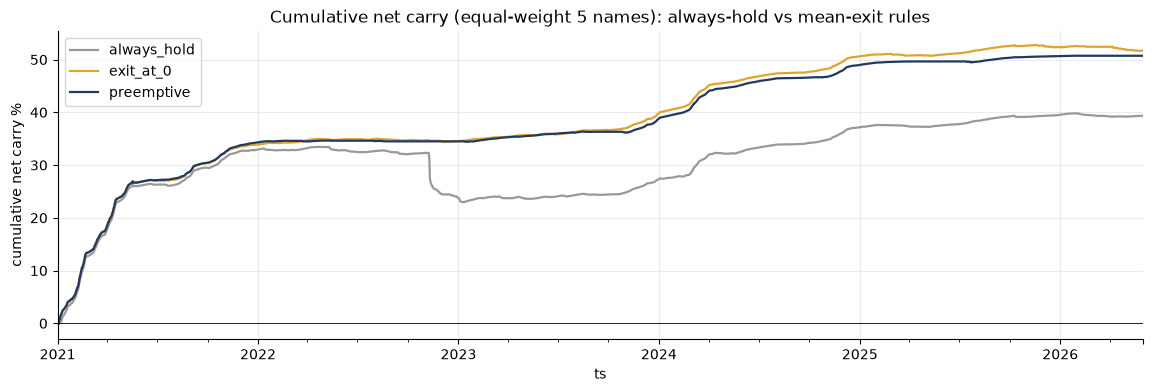

In [5]:
# Cumulative net carry: always-hold vs preemptive mean-exit (aggregate, equal-weight 5 names)
fig, ax = plt.subplots(figsize=(14,4))
for name,c in [('always_hold','0.6'),('exit_at_0',AMBER),('preemptive',NAVY)]:
    agg=None
    for s in SYMS:
        d=inc[s].dropna(); m=mean[s].reindex(d.index); r=simulate(d,m,**RULES[name])
        # net daily = held*d minus cost amortized at entries (mark cost on entry days)
        entry_days=(r['held'].diff()==1).astype(float)
        net_daily=r['held']*d - entry_days*C_RT
        agg = net_daily if agg is None else agg.add(net_daily, fill_value=0)
    (agg.cumsum()/len(SYMS)*100).plot(ax=ax, color=c, lw=1.6, label=name)
ax.axhline(0,color='k',lw=0.6); ax.set_ylabel('cumulative net carry %'); ax.legend()
ax.set_title('Cumulative net carry (equal-weight 5 names): always-hold vs mean-exit rules')
plt.show()

## The effect per asset

**Cumulative net carry per asset** under each rule — see the split: the exit rule lifts the
flip-prone names (BNB, SOL) out of their negative-funding drawdowns, while barely touching the
clean majors (BTC/ETH/XRP).

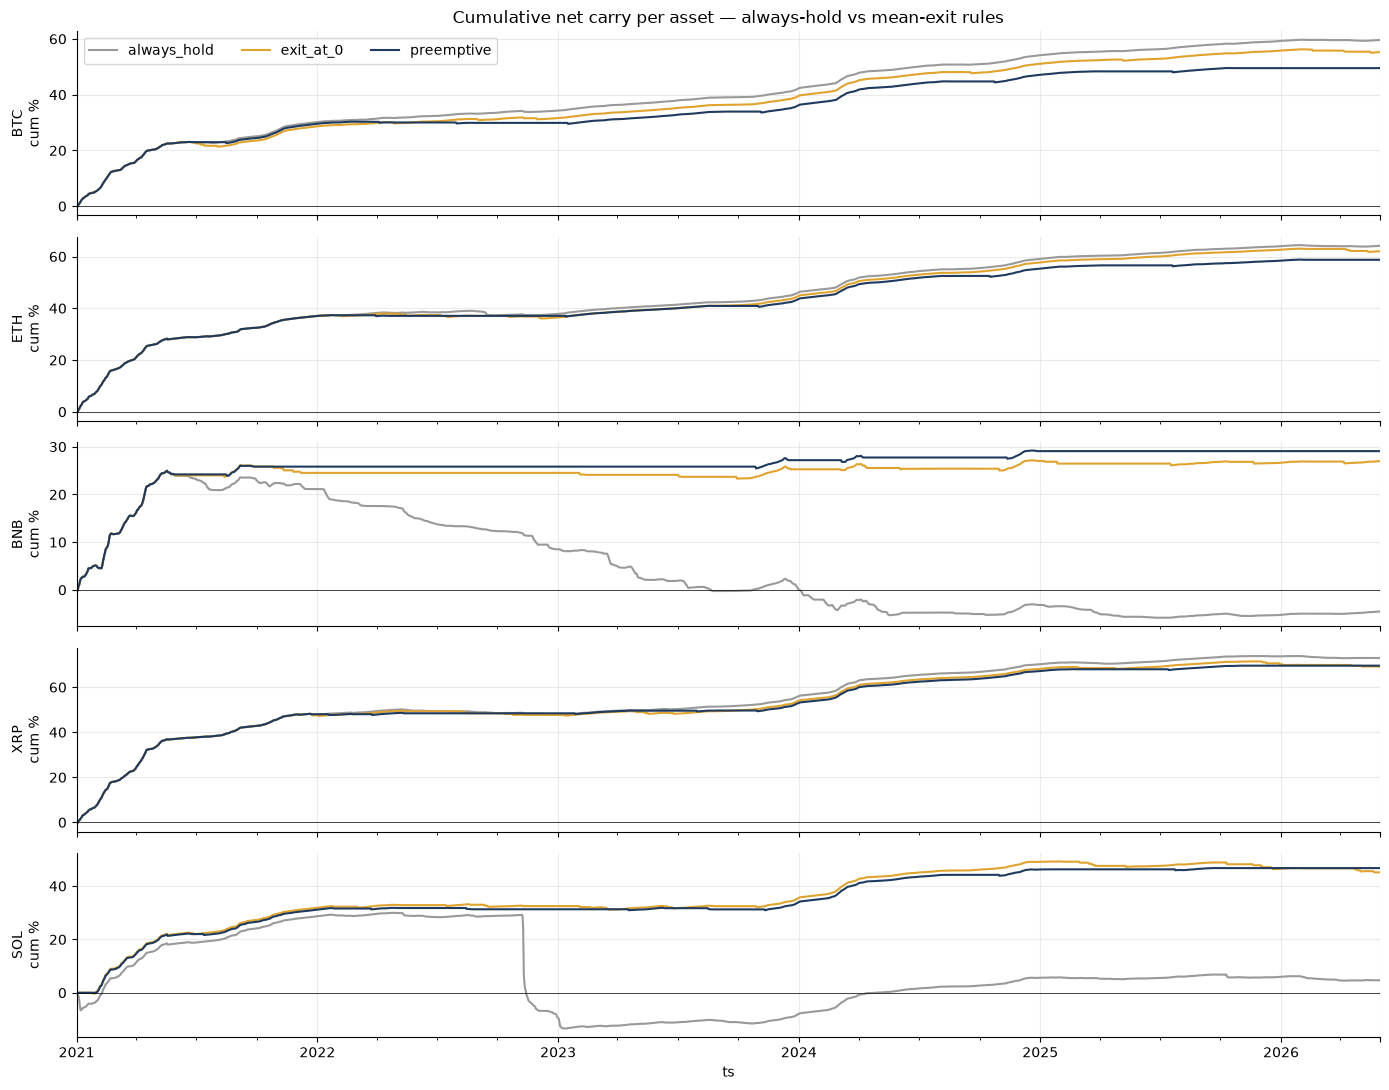

In [6]:
fig, axes = plt.subplots(len(SYMS), 1, figsize=(14, 11), sharex=True)
for ax, s in zip(axes, SYMS):
    d=inc[s].dropna(); m=mean[s].reindex(d.index)
    for name,c in [('always_hold','0.6'),('exit_at_0',AMBER),('preemptive',NAVY)]:
        r=simulate(d,m,**RULES[name]); entry=(r['held'].diff()==1).astype(float)
        ((r['held']*d - entry*C_RT).cumsum()*100).plot(ax=ax, color=c, lw=1.5, label=name)
    ax.axhline(0,color='k',lw=0.5); ax.set_ylabel(s.replace('usdt','').upper()+'\ncum %')
axes[0].legend(ncol=3, loc='upper left')
axes[0].set_title('Cumulative net carry per asset — always-hold vs mean-exit rules')
plt.tight_layout(); plt.show()

**Where the rule holds (green) vs where funding went negative (red), per asset** (preemptive
rule). The flip-prone names show long red stretches that the rule sits out; the majors are mostly
green with only brief red nicks.

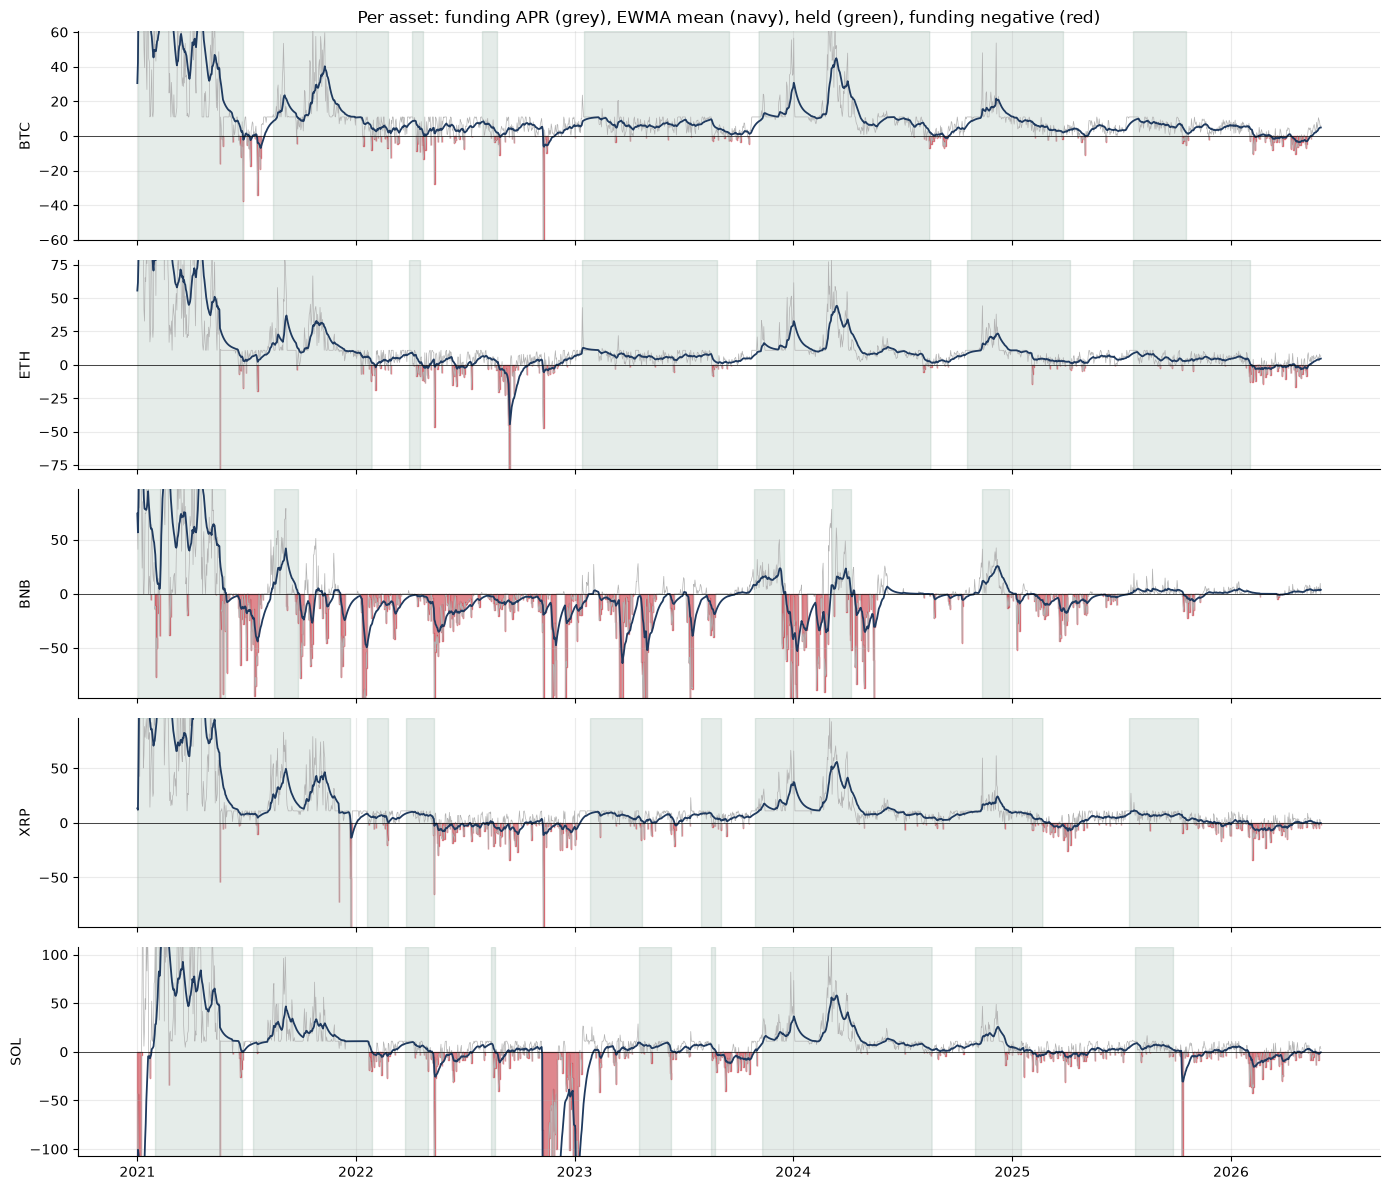

In [7]:
fig, axes = plt.subplots(len(SYMS), 1, figsize=(14, 12), sharex=True)
for ax, s in zip(axes, SYMS):
    d=inc[s].dropna(); m=mean[s].reindex(d.index); held=simulate(d,m,**RULES['preemptive'])['held']
    lim=float(np.nanpercentile(np.abs(d*365*100), 97))
    ax.plot(d.index, d*365*100, color='0.7', lw=0.5)
    ax.plot(m.index, m*365*100, color=NAVY, lw=1.3)
    ax.fill_between(d.index, -lim, lim, where=(held==1), color=GREEN, alpha=0.12, step='mid')
    ax.fill_between(d.index, (d*365*100).clip(upper=0), 0, where=(d<0), color=RED, alpha=0.5, step='mid')
    ax.axhline(0,color='k',lw=0.5); ax.set_ylim(-lim,lim); ax.set_ylabel(s.replace('usdt','').upper())
axes[0].set_title('Per asset: funding APR (grey), EWMA mean (navy), held (green), funding negative (red)')
plt.tight_layout(); plt.show()

## Takeaways

Read the table + curves:
- **`neg_paid_%`** shows how much negative funding each rule ate — the preemptive mean-exit should
  pay materially less (it dodges the flips), especially on the flip-prone names (BNB, SOL).
- **`net_apr_%`** is the bottom line after churn cost — does dodging the flips beat the forgone carry?
- **`round_trips`** is the churn the hysteresis controls.

If the preemptive rule lifts net carry and cuts the negative-funding tail at acceptable churn, this
is the **Layer D keep rule**: enter on a high mean, hold while the mean stays healthy, exit as it
reverts toward 0 — applied per name on top of the cross-sectional selection. Caveats: single-name
timing (no cross-section yet), costs are the v0 estimate, threshold/halflife not yet tuned (and must
be tuned on held-out data to avoid fitting).